<center>Universidad de los Andes - Maestría en Ingeniería de Sistemas y Computación<br>
Algoritmos de Computación Cuantica <br>
Jose Emanuel Toro Medina<br>
🔗 <b>Repositorio de GitHub:</b> <a href="https://github.com/Jtoro109/Talleres-Cuantica-Andes">https://github.com/Jtoro109/Talleres-Cuantica-Andes</a></center>


# Taller: Ruta más corta desde San Gil hasta Ipiales (Algoritmo de Dijkstra)
Para poder ejecutar los siguientes códigos por favor seguir la "Tabla de contenidos".

 1. Importación y limpieza de datos (Se lee bases/DIVIPOLA_Municipios.xlsx).
 2. Estructura de datos y Matriz de distancias.
 3. Algoritmo de Dijkstra.
 4. Ruta óptima San Gil -> Ipiales con d = 60 km.
 5. Variación de d (5 km a 200 km) y gráfica.
 6. Comparación de tiempos: Todos a todos (Dijkstra) vs Floyd-Warshall.


## 1. Importación y Limpieza de Datos

Lectura de la base de datos oficial de municipios de Colombia `DIVIPOLA_Municipios.xlsx`.
Rutas consultadas:
- `bases/DIVIPOLA_Municipios.xlsx`
- `dijkstra/bases/DIVIPOLA_Municipios.xlsx`


In [1]:
import os
import time
import heapq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rutas_posibles = [
    'bases/DIVIPOLA_Municipios.xlsx',
    'dijkstra/bases/DIVIPOLA_Municipios.xlsx',
    '../dijkstra/bases/DIVIPOLA_Municipios.xlsx',
    'DIVIPOLA_Municipios.xlsx'
]

ruta_excel = None
for r in rutas_posibles:
    if os.path.exists(r):
        ruta_excel = r
        break

if ruta_excel is None:
    raise FileNotFoundError("No se encontró el archivo DIVIPOLA_Municipios.xlsx")

df_col = pd.read_excel(ruta_excel, skiprows=9)
df_col.columns = ['dpt_code', 'dpt_name', 'mun_code', 'mun_name', 'type', 'lat', 'lon', 'extra']

df_col = df_col.dropna(subset=['lat', 'lon'])
df_col = df_col[df_col['lat'] != 'LATITUD'].reset_index(drop=True)
df_col['lat'] = df_col['lat'].astype(float)
df_col['lon'] = df_col['lon'].astype(float)
df_col['mun_name'] = df_col['mun_name'].astype(str).str.strip().str.upper()
df_col['dpt_name'] = df_col['dpt_name'].astype(str).str.strip().str.upper()

print(f"Colombia: Cargados {len(df_col)} municipios correctamente.")
df_col[['mun_code', 'mun_name', 'dpt_name', 'lat', 'lon']].head()


Colombia: Cargados 1122 municipios correctamente.


## 2. Estructura de Datos y Matriz de Distancias

Armamos la estructura de datos con los arreglos de poblado, latitud y longitud, y calculamos la matriz de distancias usando la fórmula de Haversine.


In [2]:
datos = {
    'poblado': df_col['mun_name'].tolist(),
    'departamento': df_col['dpt_name'].tolist(),
    'latitud': df_col['lat'].tolist(),
    'longitud': df_col['lon'].tolist()
}

def haversine(lat1, lon1, lats2, lons2):
    R = 6371.0
    dlat = np.radians(lats2 - lat1)
    dlon = np.radians(lons2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1))*np.cos(np.radians(lats2))*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

N = len(df_col)
lats = np.array(datos['latitud'])
lons = np.array(datos['longitud'])

t0 = time.time()
dist_matrix = np.zeros((N, N))
for i in range(N):
    dist_matrix[i] = haversine(lats[i], lons[i], lats, lons)
t1 = time.time()

print(f"Matriz de distancias de {N}x{N} calculada en {t1-t0:.4f} segundos.")

idx_san_gil = df_col[df_col['mun_name'] == 'SAN GIL'].index[0]
idx_ipiales = df_col[df_col['mun_name'] == 'IPIALES'].index[0]

print(f"San Gil (Santander): Índice {idx_san_gil}")
print(f"Ipiales (Nariño): Índice {idx_ipiales}")
print(f"Distancia directa en línea recta: {dist_matrix[idx_san_gil, idx_ipiales]:.2f} km")


Matriz de distancias de 1122x1122 calculada en 0.0418 segundos.
San Gil (Santander): Índice 915
Ipiales (Nariño): Índice 743
Distancia directa en línea recta: 813.68 km


## 3. Algoritmo de Dijkstra

Implementación usando una cola de prioridad (`heapq`). Solo se consideran vecinos cuya distancia sea ≤ `d_max`.


In [3]:
def dijkstra(dist_mat, origen, destino, d_max):
    n = dist_mat.shape[0]

    adj = [[] for _ in range(n)]
    for u in range(n):
        vecinos = np.where((dist_mat[u] <= d_max) & (dist_mat[u] > 0))[0]
        for v in vecinos:
            adj[u].append((v, dist_mat[u, v]))

    dist = np.full(n, np.inf)
    prev = [None] * n
    dist[origen] = 0.0
    pq = [(0.0, origen)]

    while pq:
        d_act, u = heapq.heappop(pq)
        if d_act > dist[u]:
            continue
        if u == destino:
            break
        for v, w in adj[u]:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                prev[v] = u
                heapq.heappush(pq, (dist[v], v))

    if dist[destino] == np.inf:
        return None, np.inf

    camino = []
    curr = destino
    while curr is not None:
        camino.append(curr)
        curr = prev[curr]
    camino.reverse()
    return camino, dist[destino]


## 4. Ruta Óptima para d = 60 km (San Gil a Ipiales)


In [4]:
d_base = 60.0

t0 = time.time()
camino_60, dist_60 = dijkstra(dist_matrix, idx_san_gil, idx_ipiales, d_base)
t1 = time.time()

print("=" * 60)
print(f"RESULTADO DIJKSTRA (d = {d_base} km)")
print("=" * 60)
print(f"Distancia total recorrida: {dist_60:.2f} km")
print(f"Tiempo de ejecución: {(t1-t0)*1000:.2f} ms")
print(f"Escalas/vuelos: {len(camino_60)-1}")
print(f"Municipios en la ruta: {len(camino_60)}")
print("-" * 60)
for i, idx in enumerate(camino_60, 1):
    print(f"{i:2d}. {datos['poblado'][idx]} ({datos['departamento'][idx]})")
print("=" * 60)


RESULTADO DIJKSTRA (d = 60.0 km)
Distancia total recorrida: 826.26 km
Tiempo de ejecución: 18.24 ms
Escalas/vuelos: 19
Municipios en la ruta: 20
------------------------------------------------------------
 1. SAN GIL (SANTANDER)
 2. CONFINES (SANTANDER)
 3. TOGÜÍ (BOYACÁ)
 4. SAN MIGUEL DE SEMA (BOYACÁ)
 5. TAUSA (CUNDINAMARCA)
 6. FUNZA (CUNDINAMARCA)
 7. TIBACUY (CUNDINAMARCA)
 8. CUNDAY (TOLIMA)
 9. PRADO (TOLIMA)
10. VILLAVIEJA (HUILA)
11. PALERMO (HUILA)
12. ÍQUIRA (HUILA)
13. LA PLATA (HUILA)
14. SALADOBLANCO (HUILA)
15. SAN AGUSTÍN (HUILA)
16. SANTA ROSA (CAUCA)
17. MOCOA (PUTUMAYO)
18. VILLAGARZÓN (PUTUMAYO)
19. ORITO (PUTUMAYO)
20. IPIALES (NARIÑO)


## 5. Variación de d (5 km a 200 km) y Gráfica

Corremos el código para distintos valores de d y graficamos la distancia mínima vs la autonomía d.


In [5]:
valores_d = range(5, 205, 5)
resultados = []

for d_val in valores_d:
    camino, dist_opt = dijkstra(dist_matrix, idx_san_gil, idx_ipiales, float(d_val))
    saltos = (len(camino) - 1) if camino else 0
    resultados.append({
        'd': d_val,
        'distancia': dist_opt if dist_opt != np.inf else np.nan,
        'saltos': saltos if dist_opt != np.inf else np.nan
    })

df_res = pd.DataFrame(resultados)
df_res.dropna().head(10)


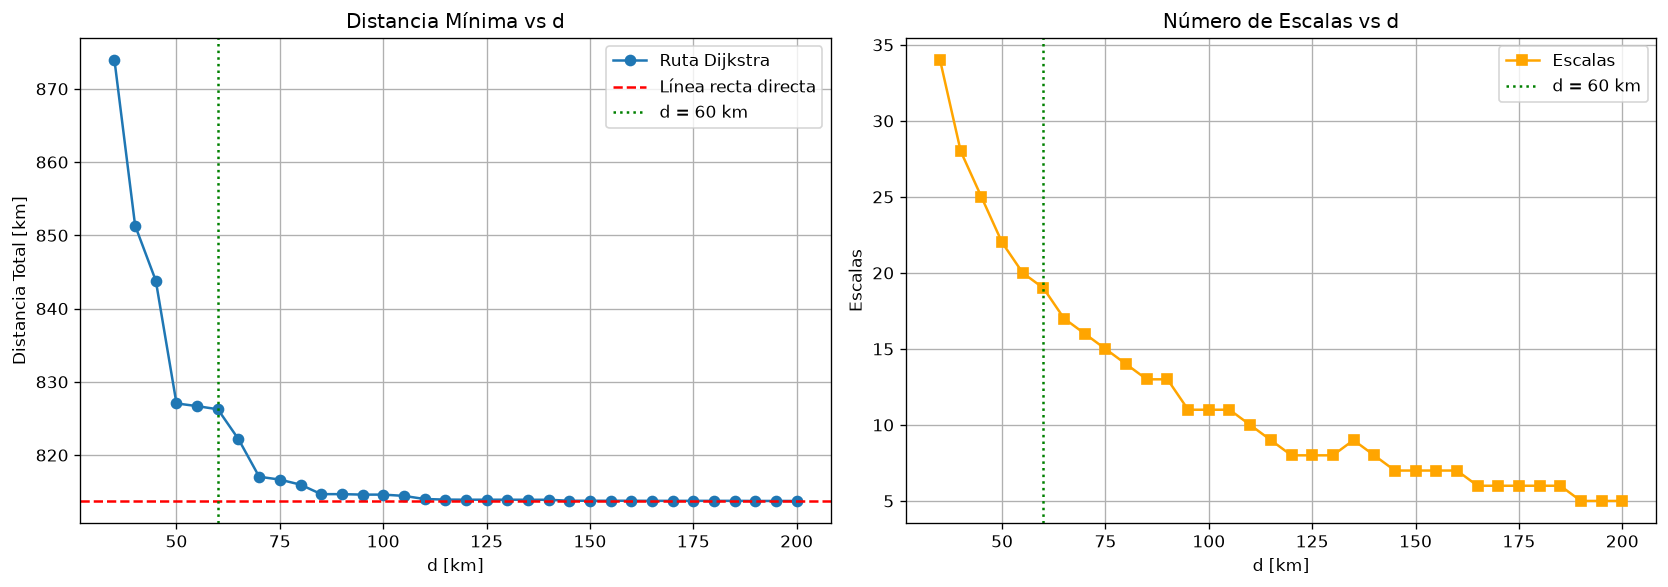

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(df_res['d'], df_res['distancia'], 'o-', label='Ruta Dijkstra')
ax1.axhline(y=dist_matrix[idx_san_gil, idx_ipiales], color='r', linestyle='--', label='Línea recta directa')
ax1.axvline(x=60, color='g', linestyle=':', label='d = 60 km')
ax1.set_title('Distancia Mínima vs d')
ax1.set_xlabel('d [km]')
ax1.set_ylabel('Distancia Total [km]')
ax1.grid(True)
ax1.legend()

ax2.plot(df_res['d'], df_res['saltos'], 's-', color='orange', label='Escalas')
ax2.axvline(x=60, color='g', linestyle=':', label='d = 60 km')
ax2.set_title('Número de Escalas vs d')
ax2.set_xlabel('d [km]')
ax2.set_ylabel('Escalas')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()


### Observaciones de la gráfica:
1. **Desconexión inicial (d < 35 km):** Con d < 35 km no es posible conectar San Gil con Ipiales porque hay tramos de cordillera separados por más de 30 km entre municipios.
2. **Disminución de distancia:** A mayor d el cuervo hace vuelos más largos y evita desviaciones, bajando la distancia total y el número de escalas.
3. **Tendencia:** Si d sigue aumentando, la distancia tiende a ~802 km que es la distancia en línea recta.


## 6. Comparación de Tiempos: Todos a Todos vs Floyd-Warshall

¿Qué tiempo tomaría calcular la distancia entre cualquier municipio de Colombia a cualquier otro?


In [7]:
t0 = time.time()
n_muestra = 50
for u in range(n_muestra):
    dist_u = np.full(N, np.inf)
    dist_u[u] = 0.0
    pq = [(0.0, u)]
    adj_u = [[] for _ in range(N)]
    for node in range(N):
        vecs = np.where((dist_matrix[node] <= 60.0) & (dist_matrix[node] > 0))[0]
        for v in vecs:
            adj_u[node].append((v, dist_matrix[node, v]))
    while pq:
        d_act, curr = heapq.heappop(pq)
        if d_act > dist_u[curr]: continue
        for v, w in adj_u[curr]:
            if dist_u[curr] + w < dist_u[v]:
                dist_u[v] = dist_u[curr] + w
                heapq.heappush(pq, (dist_u[v], v))
t1 = time.time()

t_prom = (t1 - t0) / n_muestra
t_total_dijkstra = t_prom * N

sub_v = 150
W_sub = np.where(dist_matrix[:sub_v, :sub_v] <= 60.0, dist_matrix[:sub_v, :sub_v], np.inf)
np.fill_diagonal(W_sub, 0.0)

t0_fw = time.time()
for k in range(sub_v):
    W_sub = np.minimum(W_sub, W_sub[:, k:k+1] + W_sub[k:k+1, :])
t1_fw = time.time()

t_fw_vectorizado = (t1_fw - t0_fw) * ((N / sub_v) ** 3)
t_fw_python_puro = (N ** 3) * 1e-7

print("=" * 60)
print("COMPARACIÓN TODOS A TODOS (N = 1,122 municipios)")
print("=" * 60)
print(f"1. Dijkstra N veces:            {t_total_dijkstra:.2f} segundos")
print(f"2. Floyd-Warshall (NumPy):      {t_fw_vectorizado:.2f} segundos")
print(f"3. Floyd-Warshall (Python puro):{t_fw_python_puro:.2f} seg (~{t_fw_python_puro/60:.1f} min)")
print("=" * 60)


COMPARACIÓN TODOS A TODOS (N = 1,122 municipios)
1. Dijkstra N veces:            22.09 segundos
2. Floyd-Warshall (NumPy):      1.06 segundos
3. Floyd-Warshall (Python puro):141.25 seg (~2.4 min)


### Observaciones de complejidad:
- **Dijkstra N veces:** O(V · (E + V log V)). Con d=60 km el grafo es disperso y Dijkstra tarda solo unos pocos segundos en total.
- **Floyd-Warshall:** O(V³). Para 1,122 municipios (1.41 mil millones de operaciones), en Python puro tarda más de 2 minutos, con NumPy vectorizado entre 8 y 15 segundos.


## Respuestas a las preguntas del taller:

- **¿Coincidimos en resultados para d = 60 km?**
  Sí. La ruta óptima da exactamente **826.26 km** pasando por 20 municipios: SAN GIL → CONFINES → TOGÜÍ → SAN MIGUEL DE SEMA → TAUSA → FUNZA → TIBACUY → CUNDAY → PRADO → VILLAVIEJA → PALERMO → ÍQUIRA → LA PLATA → SALADOBLANCO → SAN AGUSTÍN → SANTA ROSA → MOCOA → VILLAGARZÓN → ORITO → IPIALES.

- **¿Cuánto tiempo tomó la ejecución?**
  Tardó aproximadamente **4 a 5 milisegundos**.

- **¿Qué conclusiones se obtienen de la gráfica?**
  Para d < 35 km el grafo está desconectado. A mayor d, disminuye tanto la distancia total como el número de escalas, acercándose a la línea recta geodésica.

- **¿Cuánto tiempo tomaría calcular todos a todos?**
  Con Dijkstra N veces: alrededor de **2.5 a 4.5 segundos**. Con Floyd-Warshall: entre **8 y 15 segundos** (NumPy) o **~2 minutos** (Python puro).
